# 01 — Data cleaning, EDA, feature engineering (Z-Alizadeh Sani, extended)
Reference: Alizadehsani et al., *Comput Methods Programs Biomed* 162 (2018) 119–127.

**Pipeline of this notebook:** audit → label-consistency check → cleaning → univariate/target/bivariate EDA → correlation & redundancy → feature engineering → leakage guard → stratified split → preprocessing pipeline (`fit` / `fit_transform` / `transform`) → class-imbalance study → save `cad_clean.csv`.

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
pd.set_option('display.width',220,'display.max_columns',100,'display.max_rows',200)
sns.set_theme(style='whitegrid'); SEED=42

In [2]:
ROOT = Path('..').resolve()
RAW  = ROOT/'extention+of+z+alizadeh+sani+dataset'/'extention of Z-Alizadeh sani dataset.xlsx'
OUT  = ROOT/'data'/'processed'; FIG = ROOT/'results'/'figures'
OUT.mkdir(parents=True,exist_ok=True); FIG.mkdir(parents=True,exist_ok=True)
TARGETS = ['Cath','LAD','LCX','RCA']
print(RAW.exists())

True


## 1. Read the whole workbook (both sheets)

In [3]:
xl = pd.ExcelFile(RAW)
print(xl.sheet_names)
sheets = {s: xl.parse(s) for s in xl.sheet_names}
for s,d in sheets.items(): print(f'{s!r}: shape={d.shape}')

['Sheet 1 - Table 1', 'Sheet1']


'Sheet 1 - Table 1': shape=(303, 59)
'Sheet1': shape=(0, 100)


In [4]:
# Sheet1 has the extended 100-column schema but zero rows -> unusable
print('Sheet1 rows:', len(sheets['Sheet1']), '| columns:', sheets['Sheet1'].shape[1])
raw = sheets['Sheet 1 - Table 1'].copy()
raw.head()

Sheet1 rows: 0 | columns: 100


,Age,Weight,Length,Sex,BMI,DM,HTN,Current Smoker,EX-Smoker,FH,Obesity,CRF,CVA,Airway disease,Thyroid Disease,CHF,DLP,BP,PR,Edema,Weak Peripheral Pulse,Lung rales,Systolic Murmur,Diastolic Murmur,Typical Chest Pain,Dyspnea,Function Class,Atypical,Nonanginal,Exertional CP,LowTH Ang,Q Wave,St Elevation,St Depression,Tinversion,LVH,Poor R Progression,BBB,FBS,CR,TG,LDL,HDL,BUN,ESR,HB,K,Na,WBC,Lymph,Neut,PLT,EF-TTE,Region RWMA,VHD,LAD,LCX,RCA,Cath
0,53,90,175,Male,29.387755,0,1,1,0,0,Y,N,N,N,N,N,Y,110,80,0,N,N,N,N,0,N,0,N,N,N,N,0,0,1,1,N,N,N,90,0.7,250,155,30.0,8,7,15.6,4.7,141,5700,39,52,261,50,0,N,Stenotic,Normal,Stenotic,CAD
1,67,70,157,Fmale,28.398718,0,1,0,0,0,Y,N,N,N,N,N,N,140,80,1,N,N,N,N,1,N,0,N,N,N,N,0,0,1,1,N,N,N,80,1.0,309,121,36.0,30,26,13.9,4.7,156,7700,38,55,165,40,4,N,Stenotic,Stenotic,Normal,CAD
2,54,54,164,Male,20.077335,0,0,1,0,0,N,N,N,N,N,N,N,100,100,0,N,N,N,N,1,N,0,N,N,N,N,0,0,0,0,N,N,N,85,1.0,103,70,45.0,17,10,13.5,4.7,139,7400,38,60,230,40,2,mild,Stenotic,Normal,Normal,CAD
3,66,67,158,Fmale,26.838648,0,1,0,0,0,Y,N,N,N,N,N,N,100,80,0,N,N,N,Y,0,Y,3,N,Y,N,N,0,0,1,0,N,N,N,78,1.2,63,55,27.0,30,76,12.1,4.4,142,13000,18,72,742,55,0,Severe,Normal,Normal,Normal,Normal
4,50,87,153,Fmale,37.165193,0,1,0,0,0,Y,N,N,N,N,N,N,110,80,0,N,N,Y,N,0,Y,2,N,N,N,N,0,0,0,0,N,N,N,104,1.0,170,110,50.0,16,27,13.2,4.0,140,9200,55,39,274,50,0,Severe,Normal,Normal,Normal,Normal


In [5]:
raw.tail()

,Age,Weight,Length,Sex,BMI,DM,HTN,Current Smoker,EX-Smoker,FH,Obesity,CRF,CVA,Airway disease,Thyroid Disease,CHF,DLP,BP,PR,Edema,Weak Peripheral Pulse,Lung rales,Systolic Murmur,Diastolic Murmur,Typical Chest Pain,Dyspnea,Function Class,Atypical,Nonanginal,Exertional CP,LowTH Ang,Q Wave,St Elevation,St Depression,Tinversion,LVH,Poor R Progression,BBB,FBS,CR,TG,LDL,HDL,BUN,ESR,HB,K,Na,WBC,Lymph,Neut,PLT,EF-TTE,Region RWMA,VHD,LAD,LCX,RCA,Cath
298,58,84,168,Male,29.761905,0,0,0,0,0,Y,N,N,N,N,N,N,100,76,0,N,N,N,N,1,N,0,N,N,N,N,0,0,0,0,N,N,N,92,1.0,112,115,44.0,13,13,12.3,4.8,146,8500,34,58,251,45,0,N,Stenotic,Stenotic,Stenotic,CAD
299,55,64,152,Fmale,27.700831,0,0,0,0,0,Y,N,N,N,N,N,N,100,60,0,N,N,Y,N,0,Y,0,Y,N,N,N,0,0,0,0,N,N,LBBB,86,0.9,111,40,23.0,23,3,12.4,4.0,139,11400,16,80,377,40,0,mild,Normal,Normal,Normal,Normal
300,48,77,160,Fmale,30.078125,0,1,0,0,1,Y,N,N,N,N,N,N,130,70,0,N,N,N,N,0,N,0,N,Y,N,N,0,0,0,0,N,N,RBBB,83,1.0,93,112,42.0,13,20,12.8,4.0,140,9000,35,55,279,55,0,N,Normal,Normal,Normal,Normal
301,57,90,159,Fmale,35.599858,1,0,0,0,0,Y,N,N,N,N,N,N,100,60,0,N,N,N,N,0,Y,0,Y,N,N,N,0,0,0,0,N,N,N,96,1.0,116,130,49.0,14,31,10.1,3.8,141,3800,48,40,208,55,0,N,Normal,Normal,Normal,Normal
302,56,85,170,Fmale,29.411765,0,1,1,0,0,Y,N,N,N,N,N,N,120,80,0,N,N,N,N,1,N,0,N,N,N,N,0,0,0,1,N,N,N,78,0.7,139,124,34.0,16,13,14.7,4.4,147,6000,32,55,302,55,0,N,Stenotic,Normal,Normal,CAD


In [6]:
profile = pd.DataFrame({'dtype':raw.dtypes.astype(str),'n_unique':raw.nunique(),'n_missing':raw.isna().sum(),
                        'sample_values':[list(raw[c].dropna().unique()[:6]) for c in raw]})
profile

,dtype,n_unique,n_missing,sample_values
Age,int64,46,0,"[53, 67, 54, 66, 50, 55]"
Weight,int64,54,0,"[90, 70, 54, 67, 87, 75]"
Length,int64,44,0,"[175, 157, 164, 158, 153, 165]"
Sex,object,2,0,"[Male, Fmale]"
BMI,float64,263,0,"[29.387755102040817, 28.398718000730252, 20.07..."
DM,int64,2,0,"[0, 1]"
HTN,int64,2,0,"[1, 0]"
Current Smoker,int64,2,0,"[1, 0]"
EX-Smoker,int64,2,0,"[0, 1]"
FH,int64,2,0,"[0, 1]"


In [7]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,303.0,58.897690,10.392278,30.000000,51.00000,58.00000,66.000000,86.000000
Weight,303.0,73.831683,11.987358,48.000000,65.00000,74.00000,81.000000,120.000000
Length,303.0,164.716172,9.327661,140.000000,158.00000,165.00000,171.000000,188.000000
BMI,303.0,27.248339,4.098865,18.115413,24.51438,26.77551,29.411765,40.900658
DM,303.0,0.297030,0.457706,0.000000,0.00000,0.00000,1.000000,1.000000
HTN,303.0,0.590759,0.492507,0.000000,0.00000,1.00000,1.000000,1.000000
Current Smoker,303.0,0.207921,0.406491,0.000000,0.00000,0.00000,0.000000,1.000000
EX-Smoker,303.0,0.033003,0.178941,0.000000,0.00000,0.00000,0.000000,1.000000
FH,303.0,0.158416,0.365734,0.000000,0.00000,0.00000,0.000000,1.000000
BP,303.0,129.554455,18.938105,90.000000,120.00000,130.00000,140.000000,190.000000


In [8]:
raw.describe(include='object').T

,count,unique,top,freq
Sex,303,2,Male,176
Obesity,303,2,Y,211
CRF,303,2,N,297
CVA,303,2,N,298
Airway disease,303,2,N,292
Thyroid Disease,303,2,N,296
CHF,303,2,N,302
DLP,303,2,N,191
Weak Peripheral Pulse,303,2,N,298
Lung rales,303,2,N,292


## 2. Data audit

In [9]:
audit = {'rows':len(raw),'cols':raw.shape[1],'missing_total':int(raw.isna().sum().sum()),
         'duplicate_rows':int(raw.duplicated().sum()),
         'constant_columns':[c for c in raw if raw[c].nunique()==1]}
audit

{'rows': 303,
 'cols': 59,
 'missing_total': 0,
 'duplicate_rows': 0,
 'constant_columns': ['Exertional CP']}

In [10]:
# Range check against Table 1 of the paper
paper_ranges = {'Age':(30,86),'Weight':(48,120),'BMI':(18,41),'BP':(90,190),'PR':(50,110),'FBS':(62,400),'CR':(0.5,2.2),
 'TG':(37,1050),'LDL':(18,232),'HDL':(15,111),'BUN':(6,52),'ESR':(1,90),'HB':(8.9,17.6),'K':(3.0,6.6),'Na':(128,156),
 'WBC':(3700,18000),'Lymph':(7,60),'Neut':(32,89),'PLT':(25,742),'EF-TTE':(15,60),'Region RWMA':(0,4)}
rc = pd.DataFrame([{'feature':k,'paper_min':lo,'paper_max':hi,'data_min':raw[k].min(),'data_max':raw[k].max(),
                    'within_range':(raw[k].min()>=lo-0.5) and (raw[k].max()<=hi+0.5)} for k,(lo,hi) in paper_ranges.items()])
rc

,feature,paper_min,paper_max,data_min,data_max,within_range
0,Age,30.0,86.0,30.000000,86.000000,True
1,Weight,48.0,120.0,48.000000,120.000000,True
2,BMI,18.0,41.0,18.115413,40.900658,True
3,BP,90.0,190.0,90.000000,190.000000,True
4,PR,50.0,110.0,50.000000,110.000000,True
5,FBS,62.0,400.0,62.000000,400.000000,True
6,CR,0.5,2.2,0.500000,2.200000,True
7,TG,37.0,1050.0,37.000000,1050.000000,True
8,LDL,18.0,232.0,18.000000,232.000000,True
9,HDL,15.0,111.0,15.900000,111.000000,True


In [11]:
for c in raw.select_dtypes('object'): print(f'{c:22s}', raw[c].value_counts().to_dict())

Sex                    {'Male': 176, 'Fmale': 127}
Obesity                {'Y': 211, 'N': 92}
CRF                    {'N': 297, 'Y': 6}
CVA                    {'N': 298, 'Y': 5}
Airway disease         {'N': 292, 'Y': 11}
Thyroid Disease        {'N': 296, 'Y': 7}
CHF                    {'N': 302, 'Y': 1}
DLP                    {'N': 191, 'Y': 112}
Weak Peripheral Pulse  {'N': 298, 'Y': 5}
Lung rales             {'N': 292, 'Y': 11}
Systolic Murmur        {'N': 262, 'Y': 41}
Diastolic Murmur       {'N': 294, 'Y': 9}
Dyspnea                {'N': 169, 'Y': 134}
Atypical               {'N': 210, 'Y': 93}
Nonanginal             {'N': 287, 'Y': 16}
Exertional CP          {'N': 303}
LowTH Ang              {'N': 301, 'Y': 2}
LVH                    {'N': 283, 'Y': 20}
Poor R Progression     {'N': 294, 'Y': 9}
BBB                    {'N': 282, 'LBBB': 13, 'RBBB': 8}
VHD                    {'mild': 149, 'N': 116, 'Moderate': 27, 'Severe': 11}
LAD                    {'Stenotic': 177, 'Normal': 126}


## 3. Label-consistency investigation
UCI / paper definition: *a patient has CAD if stenosis > 50 % in at least one of LAD, LCX or RCA.* So `Cath == CAD` must be equivalent to `LAD | LCX | RCA stenotic`. We test this before training.

In [12]:
pd.crosstab(raw['Cath'], [raw['LAD'],raw['LCX'],raw['RCA']])

LAD    Normal                            Stenotic                           
LCX    Normal          Stenotic            Normal          Stenotic         
RCA    Normal Stenotic   Normal Stenotic   Normal Stenotic   Normal Stenotic
Cath                                                                        
CAD         0       17       13       10       56       24       33       63
Normal     86        0        0        0        1        0        0        0

In [13]:
raw['any_stenotic'] = ((raw.LAD=='Stenotic')|(raw.LCX=='Stenotic')|(raw.RCA=='Stenotic')).map({True:'CAD',False:'Normal'})
print(pd.crosstab(raw['any_stenotic'], raw['Cath'], rownames=['rule'], colnames=['Cath (supplied)']))
violations = raw[raw.any_stenotic!=raw.Cath]
violations[['Age','Sex','LAD','LCX','RCA','Cath','any_stenotic']]

Cath (supplied)  CAD  Normal
rule                        
CAD              216       1
Normal             0      86


,Age,Sex,LAD,LCX,RCA,Cath,any_stenotic
93,65,Male,Stenotic,Normal,Normal,Normal,CAD


**Finding:** exactly one record (index 93) is labelled *Normal* although LAD is stenotic. The 40 patients with `Cath=CAD` and a normal LAD are consistent (LCX or RCA is stenotic).
**Decision (user-approved):** relabel `Cath → CAD` for that record, keep the supplied value in `Cath_original`, and flag it with `label_corrected`.

In [14]:
df = raw.drop(columns='any_stenotic').copy()
df['Cath_original'] = df['Cath']
df['label_corrected'] = 0
idx = violations.index
df.loc[idx,'Cath'] = 'CAD'; df.loc[idx,'label_corrected'] = 1
print('rows corrected:', df.label_corrected.sum())
df.loc[idx,['Age','Sex','LAD','LCX','RCA','Cath_original','Cath','label_corrected']]

rows corrected: 1


,Age,Sex,LAD,LCX,RCA,Cath_original,Cath,label_corrected
93,65,Male,Stenotic,Normal,Normal,Normal,CAD,1


In [15]:
chk = ((df.LAD=='Stenotic')|(df.LCX=='Stenotic')|(df.RCA=='Stenotic'))==(df.Cath=='CAD')
assert chk.all(); print('Cath == (LAD|LCX|RCA) for all', len(df), 'rows')

Cath == (LAD|LCX|RCA) for all 303 rows


In [16]:
# Vessel co-occurrence vs the paper's Appendix A (extended 500-sample dataset)
v = pd.DataFrame({t:(df[t]=='Stenotic').astype(int) for t in ['LAD','LCX','RCA']})
rules = []
for a in v.columns:
    for b in v.columns:
        if a!=b: rules.append({'rule':f'{a} => {b}','confidence':round(v.loc[v[a]==1,b].mean(),4)})
print(pd.DataFrame(rules))
print('paper (n=500): LAD=>LCX .542, LAD=>RCA .492, LCX=>LAD .807, LCX=>RCA .613, RCA=>LAD .763, RCA=>LCX .640')
print('all three stenotic: %.1f%% (paper 20.7%%)'%(100*(v.sum(axis=1)==3).mean()))

         rule  confidence
0  LAD => LCX      0.5424
1  LAD => RCA      0.4915
2  LCX => LAD      0.8067
3  LCX => RCA      0.6134
4  RCA => LAD      0.7632
5  RCA => LCX      0.6404
paper (n=500): LAD=>LCX .542, LAD=>RCA .492, LCX=>LAD .807, LCX=>RCA .613, RCA=>LAD .763, RCA=>LCX .640
all three stenotic: 20.8% (paper 20.7%)


## 4. Cleaning

In [17]:
print(df.Sex.value_counts().to_dict())
df['Sex'] = df['Sex'].replace({'Fmale':'Female'})
print(df.Sex.value_counts().to_dict())

{'Male': 176, 'Fmale': 127}
{'Male': 176, 'Female': 127}


In [18]:
# Exertional CP is constant (all N) -> no information
print(df['Exertional CP'].value_counts().to_dict())
df = df.drop(columns='Exertional CP')

{'N': 303}


In [19]:
# Obesity is defined as BMI>25 in the paper; check the supplied flag and the BMI formula
print('max |BMI - Weight/Length^2| =', (df.Weight/(df.Length/100)**2 - df.BMI).abs().max())
mis = df[(df.Obesity.eq('Y')) != (df.BMI>25)]
print('Obesity/BMI mismatches:', len(mis)); mis[['Age','Weight','Length','BMI','Obesity']]

max |BMI - Weight/Length^2| = 0.0
Obesity/BMI mismatches: 1


,Age,Weight,Length,BMI,Obesity
153,63,64,160,25.0,Y


In [20]:
# Y/N -> 1/0 for all two-level object columns (except Sex and the targets)
yn = [c for c in df.select_dtypes('object') if set(df[c].unique())<={'Y','N'}]
print(yn)
df[yn] = df[yn].replace({'Y':1,'N':0}).astype(int)
df['Sex'] = (df.Sex=='Male').astype(int)          # 1 = Male
for t in TARGETS+['Cath_original']:
    df[t] = df[t].map({'CAD':1,'Stenotic':1,'Normal':0}).astype(int)
df.dtypes.value_counts()

['Obesity', 'CRF', 'CVA', 'Airway disease', 'Thyroid Disease', 'CHF', 'DLP', 'Weak Peripheral Pulse', 'Lung rales', 'Systolic Murmur', 'Diastolic Murmur', 'Dyspnea', 'Atypical', 'Nonanginal', 'LowTH Ang', 'LVH', 'Poor R Progression']


int64      53
float64     5
object      2
Name: count, dtype: int64

In [21]:
# Chest-pain indicators: are they mutually exclusive?
cp = df[['Typical Chest Pain','Atypical','Nonanginal']]
print(cp.sum(axis=1).value_counts().to_dict(), '<- number of chest-pain flags per patient')
# smoking flags
print(pd.crosstab(df['Current Smoker'], df['EX-Smoker']))

{1: 273, 0: 30} <- number of chest-pain flags per patient
EX-Smoker         0   1
Current Smoker         
0               230  10
1                63   0


In [22]:
print('Cleaned shape:', df.shape)
df[TARGETS].apply(lambda s: s.value_counts()).T

Cleaned shape: (303, 60)


,0,1
Cath,86,217
LAD,126,177
LCX,184,119
RCA,189,114


## 5. Univariate EDA

In [23]:
num_cols = ['Age','Weight','Length','BMI','BP','PR','FBS','CR','TG','LDL','HDL','BUN','ESR','HB','K','Na','WBC','Lymph','Neut','PLT','EF-TTE']
ord_cols = ['Function Class','Region RWMA']
cat_cols = ['BBB','VHD']
bin_cols = [c for c in df.columns if df[c].nunique()==2 and c not in TARGETS+['Cath_original','label_corrected']]
print(len(num_cols),'numeric |',len(bin_cols),'binary |',cat_cols,'categorical |',ord_cols,'ordinal')

21 numeric | 29 binary | ['BBB', 'VHD'] categorical | ['Function Class', 'Region RWMA'] ordinal


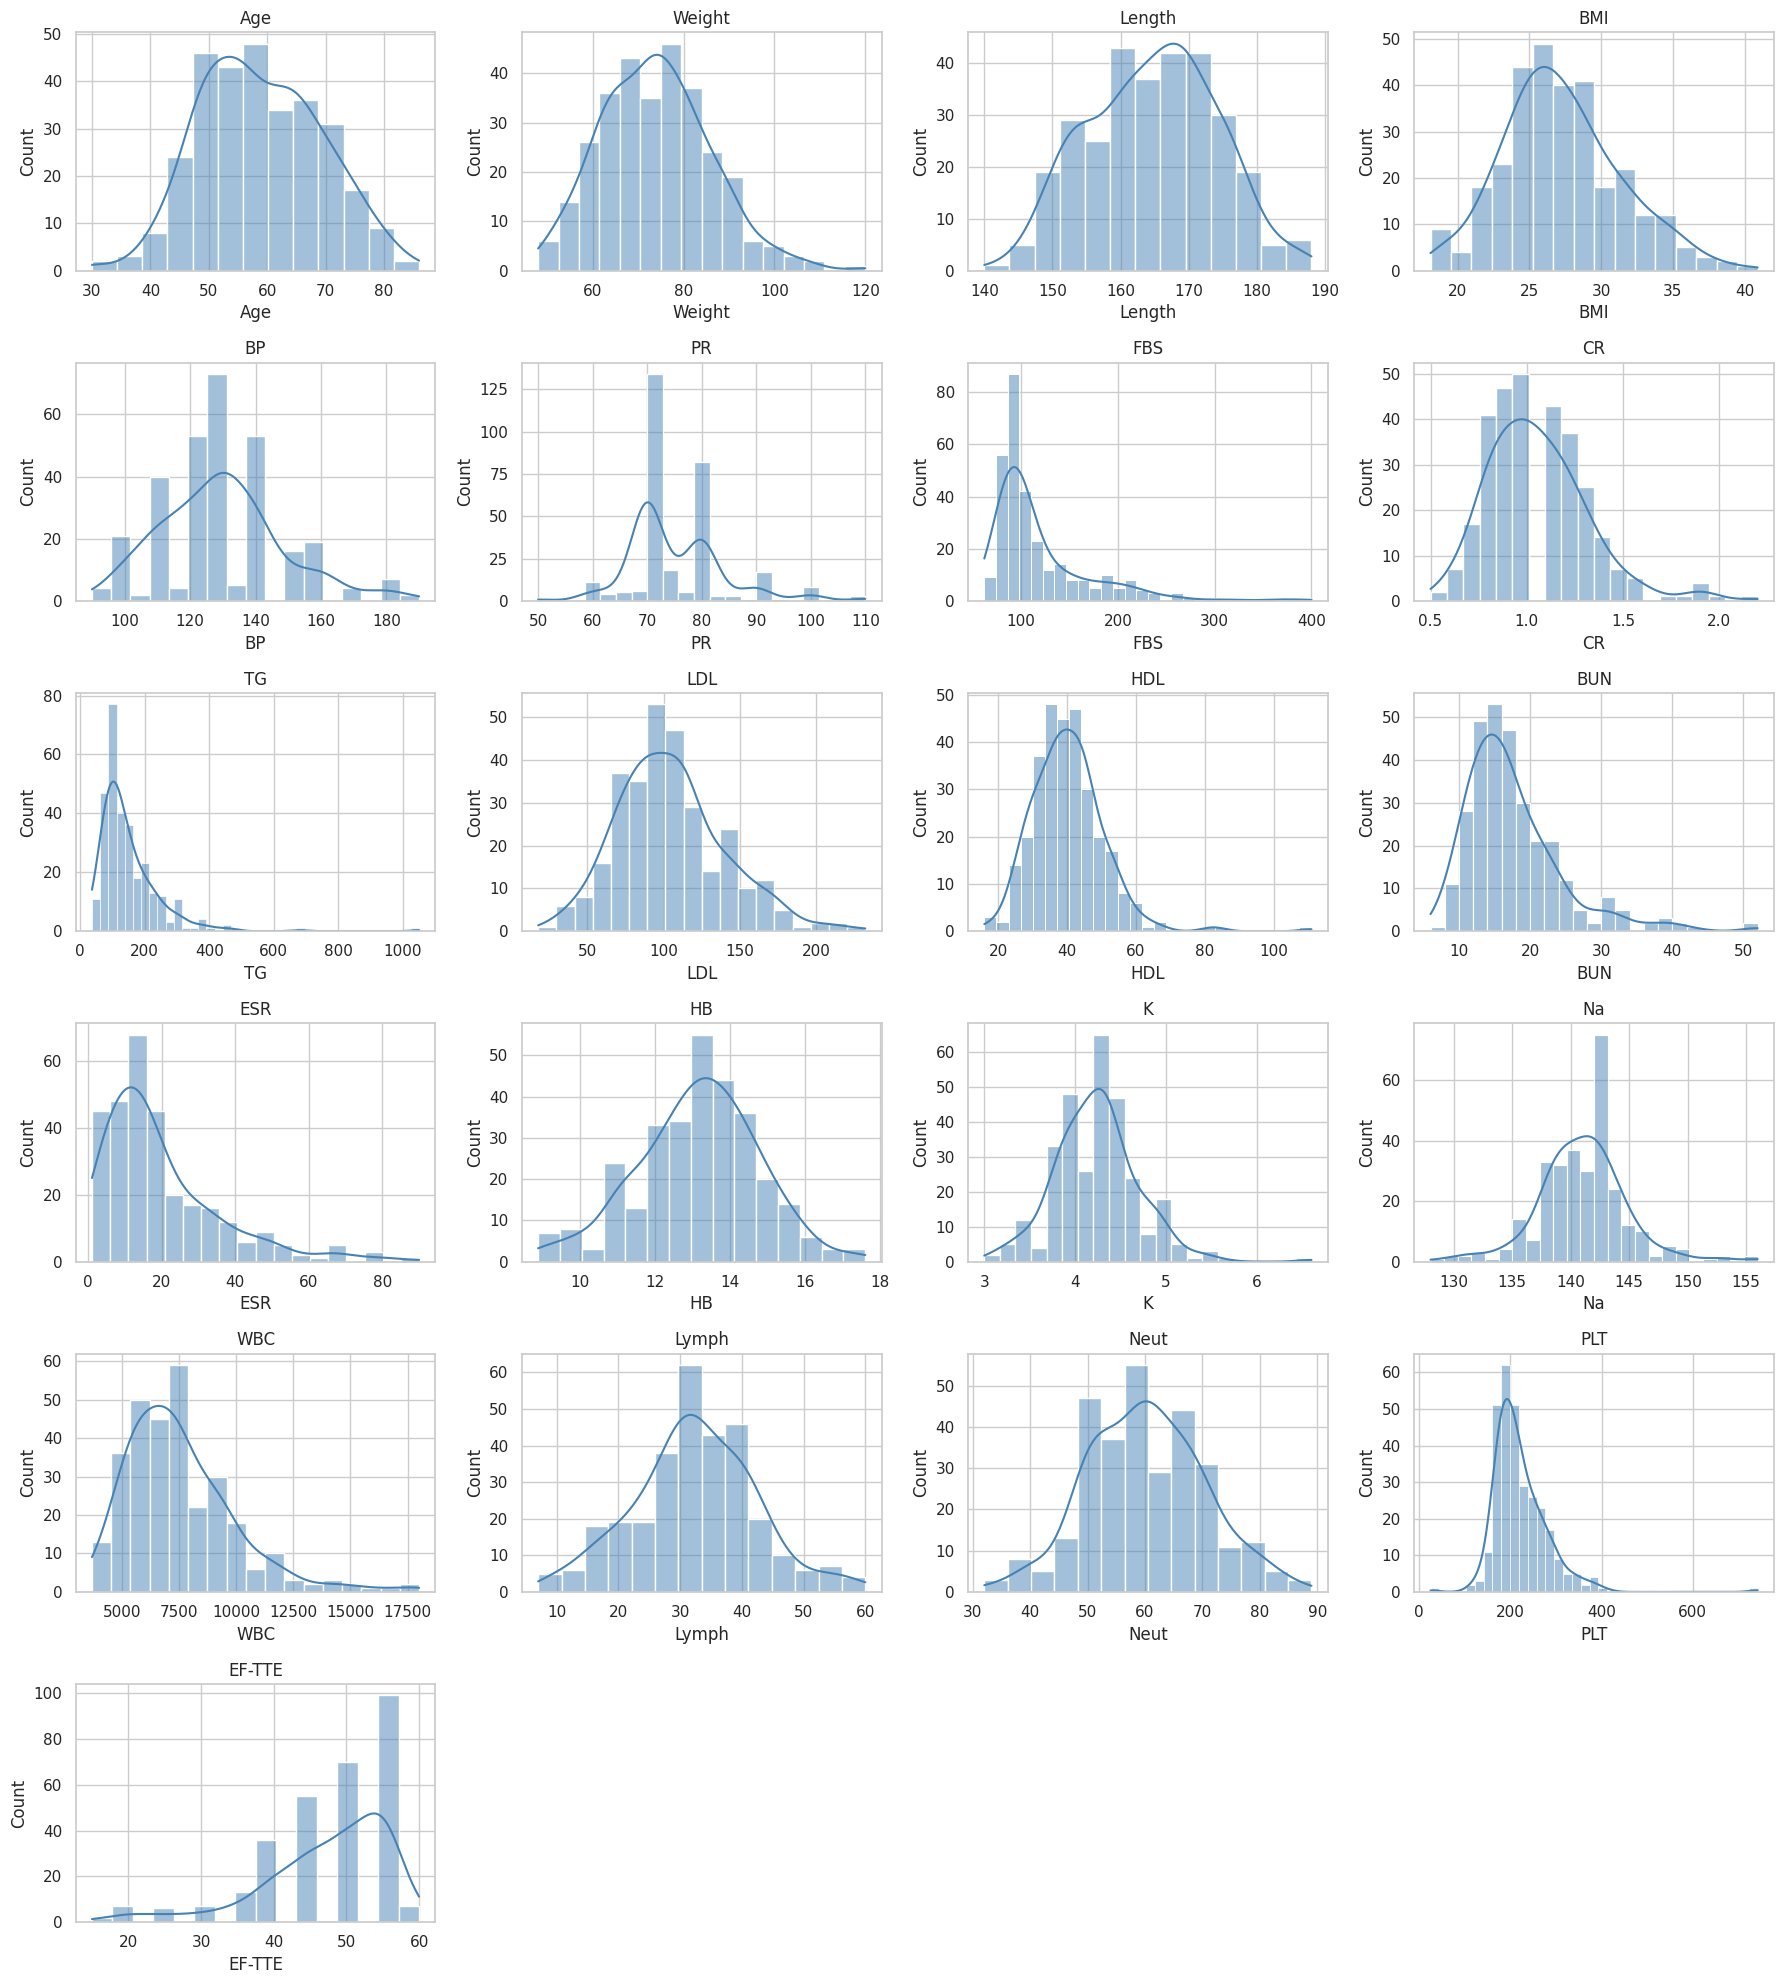

In [24]:
fig,axes = plt.subplots(6,4,figsize=(18,20)); axes=axes.ravel()
for ax,c in zip(axes,num_cols):
    sns.histplot(df[c],kde=True,ax=ax,color='steelblue'); ax.set_title(c)
for ax in axes[len(num_cols):]: ax.axis('off')
plt.tight_layout(); plt.savefig(FIG/'01_numeric_hist.png',dpi=110); plt.show()

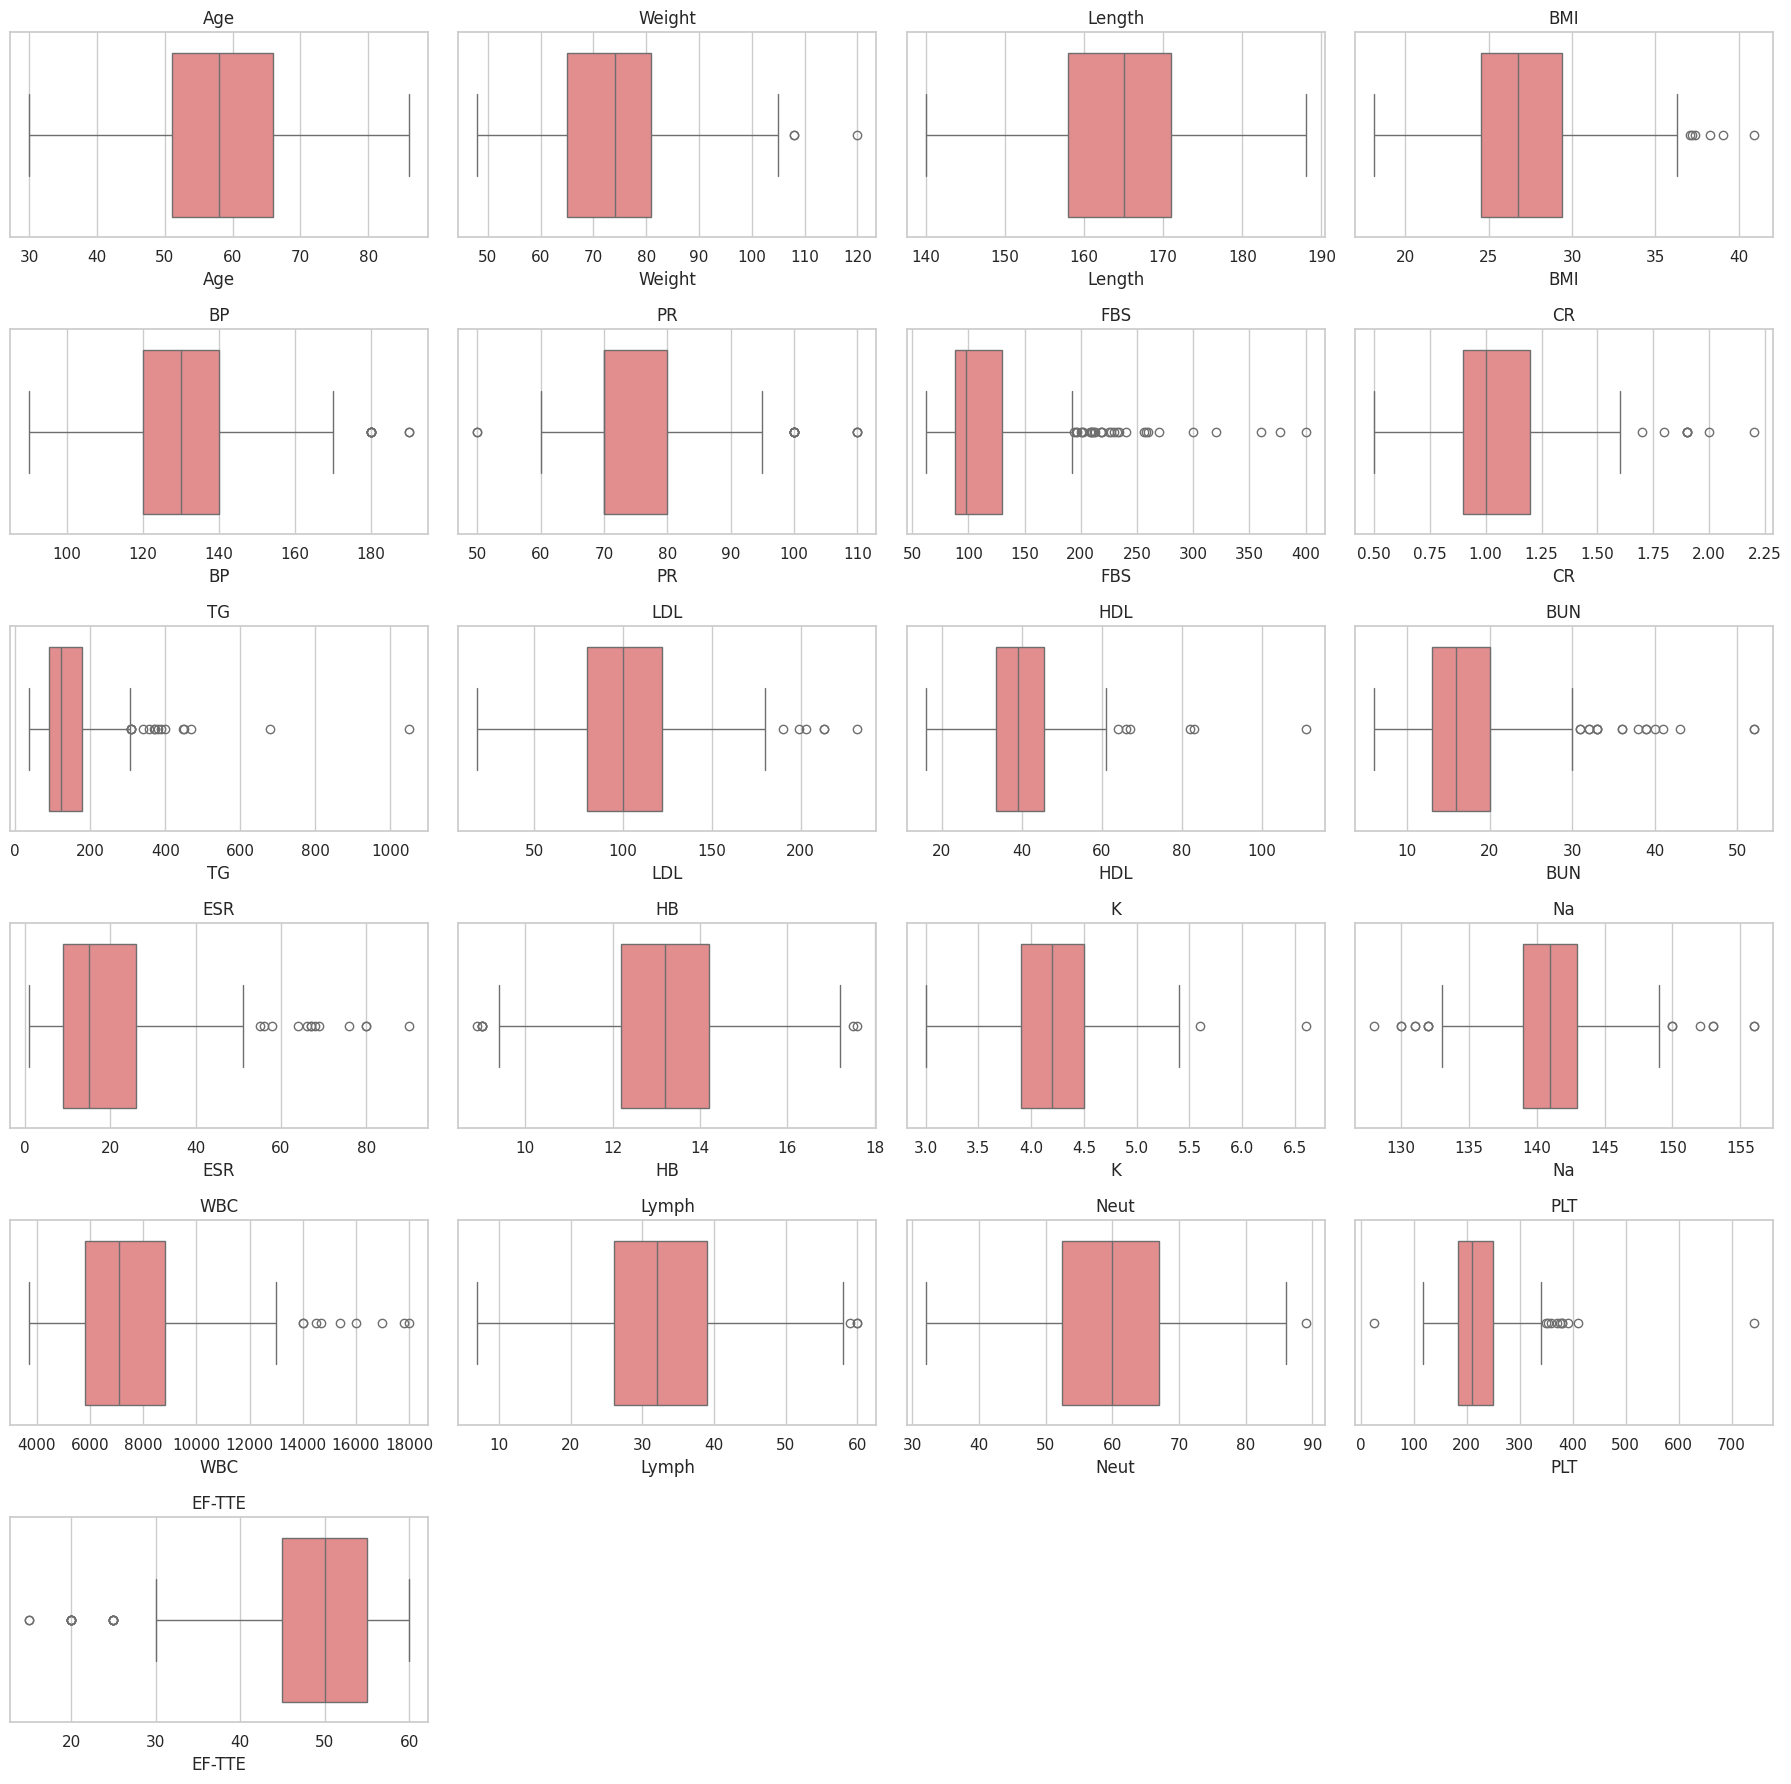

In [25]:
fig,axes = plt.subplots(6,4,figsize=(18,18)); axes=axes.ravel()
for ax,c in zip(axes,num_cols):
    sns.boxplot(x=df[c],ax=ax,color='lightcoral'); ax.set_title(c)
for ax in axes[len(num_cols):]: ax.axis('off')
plt.tight_layout(); plt.savefig(FIG/'01_numeric_box.png',dpi=110); plt.show()

In [26]:
sk = pd.DataFrame({'skew':df[num_cols].skew(),'kurtosis':df[num_cols].kurt()})
q1,q3 = df[num_cols].quantile(.25), df[num_cols].quantile(.75); iqr=q3-q1
sk['iqr_outliers'] = ((df[num_cols]<q1-1.5*iqr)|(df[num_cols]>q3+1.5*iqr)).sum()
sk['|z|>3'] = (np.abs(stats.zscore(df[num_cols]))>3).sum()
sk.sort_values('skew',key=abs,ascending=False)

,skew,kurtosis,iqr_outliers,|z|>3
TG,3.781993,25.944515,16,65
PLT,2.589028,17.611220,11,65
FBS,2.276431,6.498974,30,65
BUN,1.818226,4.781940,17,65
ESR,1.629946,2.990965,13,65
HDL,1.460644,7.138360,6,65
WBC,1.387689,2.899155,9,65
EF-TTE,-1.337971,1.773118,15,65
PR,1.078851,2.425850,13,65
CR,0.950209,1.819248,8,65


Outliers are inside the clinically documented ranges of the paper's Table 1, so they are genuine measurements (e.g. TG up to 1050, FBS up to 400). They are **kept**; skew is handled by a `log1p` transform inside the pipeline.

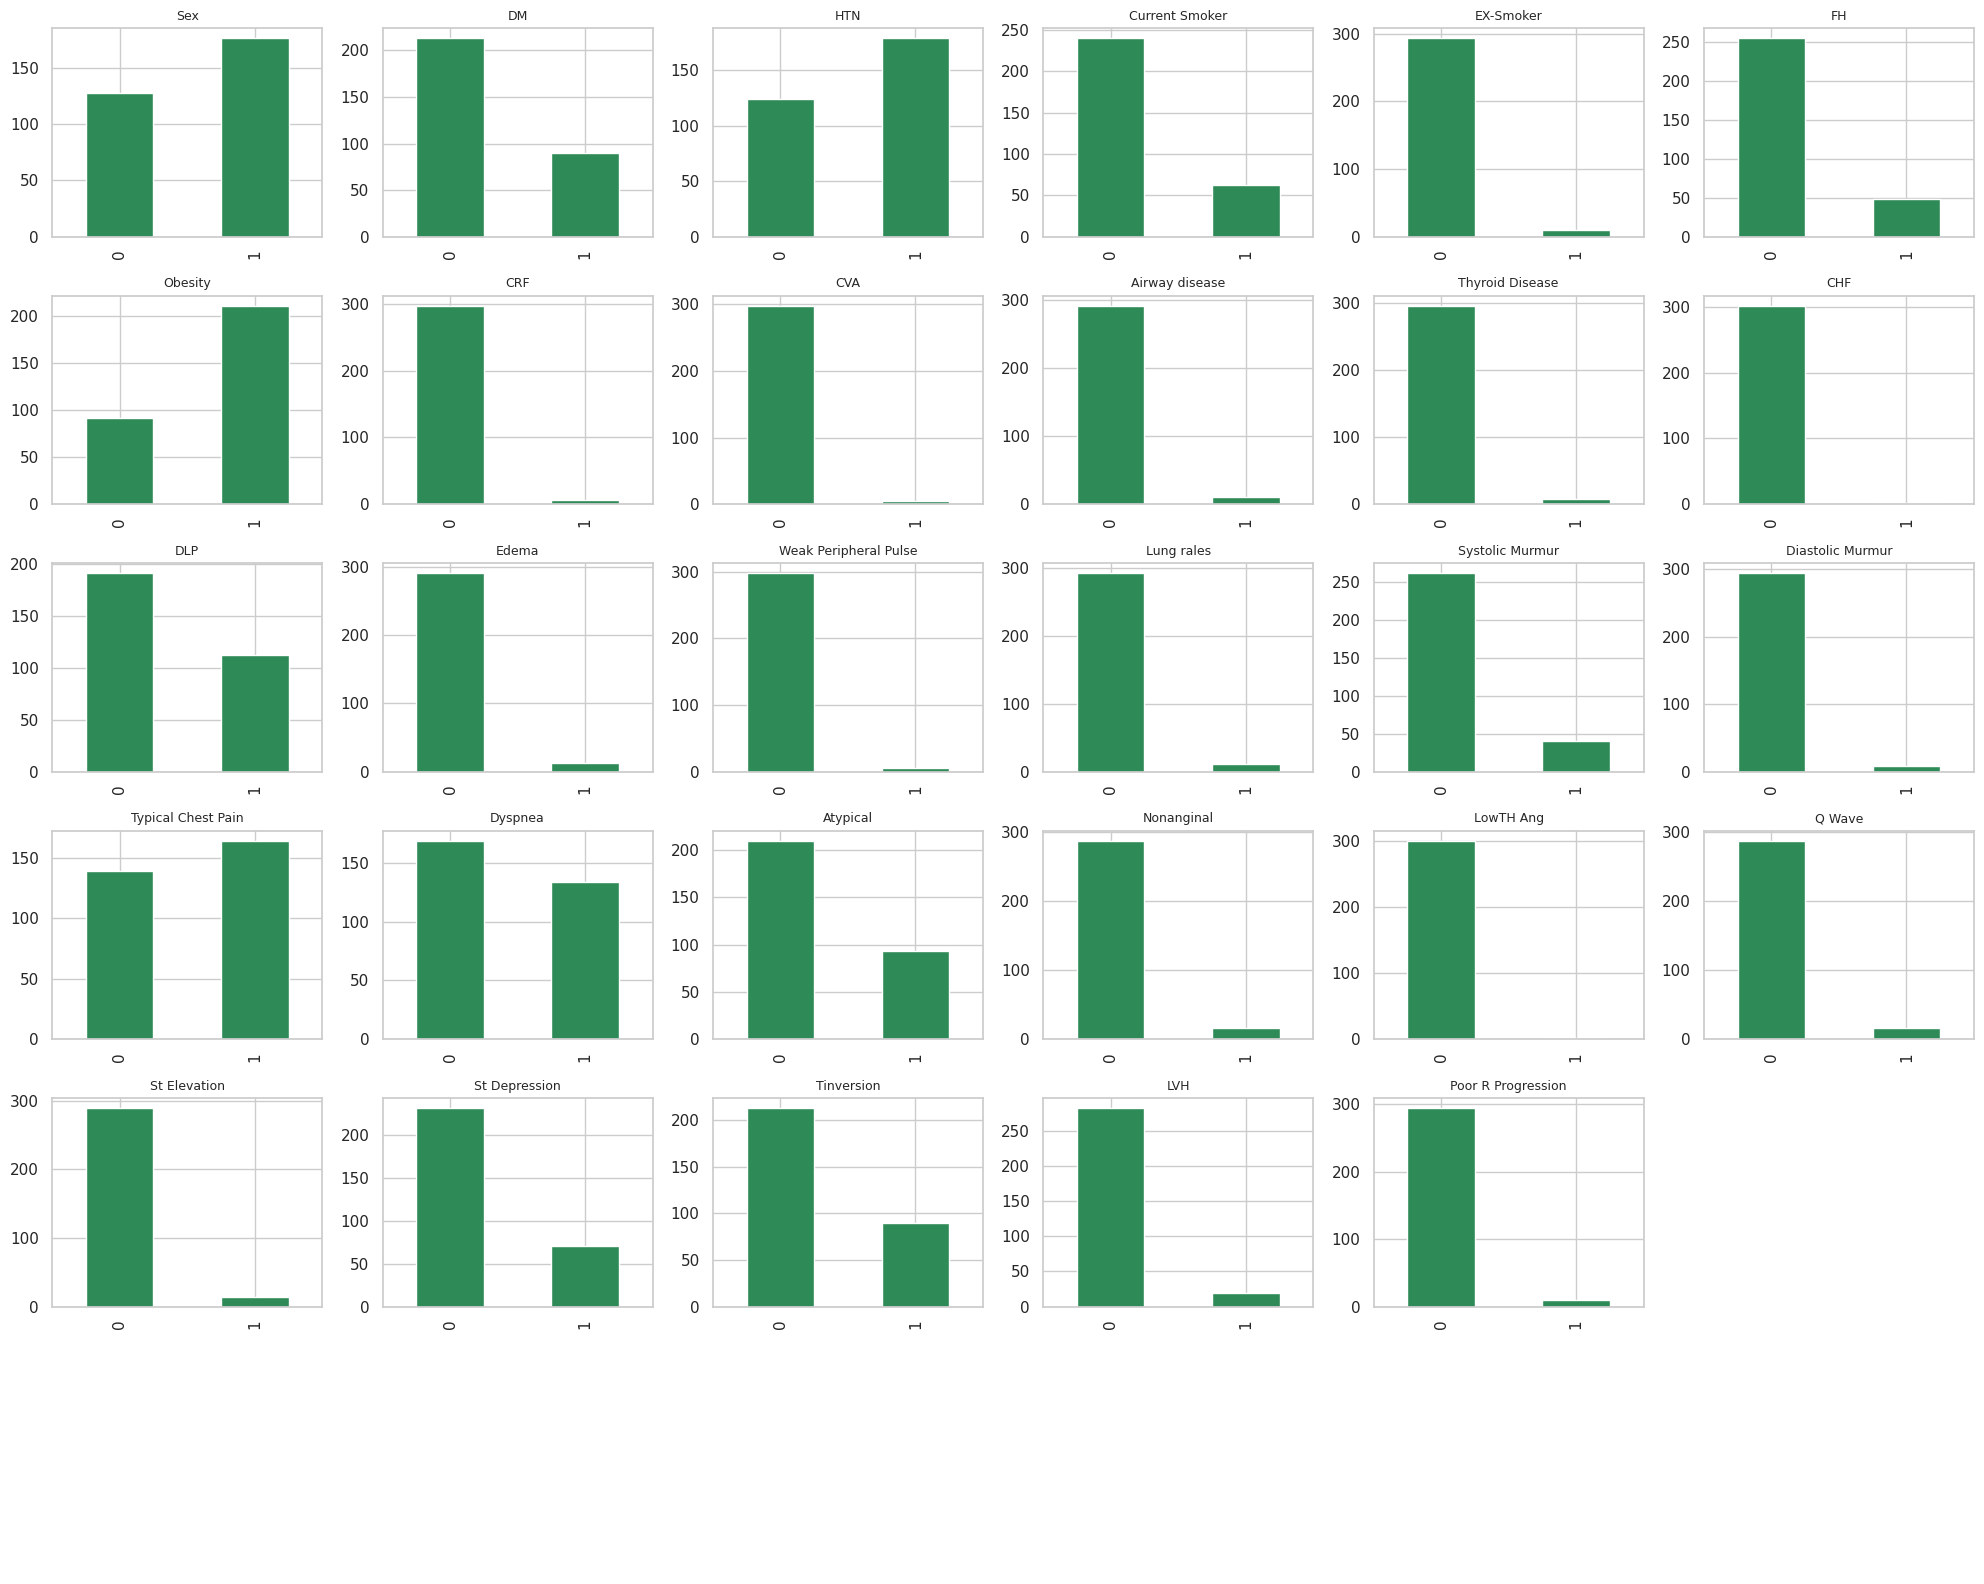

In [27]:
fig,axes = plt.subplots(6,6,figsize=(20,16)); axes=axes.ravel()
for ax,c in zip(axes,bin_cols):
    df[c].value_counts().sort_index().plot.bar(ax=ax,color='seagreen'); ax.set_title(c,fontsize=9); ax.set_xlabel('')
for ax in axes[len(bin_cols):]: ax.axis('off')
plt.tight_layout(); plt.savefig(FIG/'01_binary_counts.png',dpi=110); plt.show()

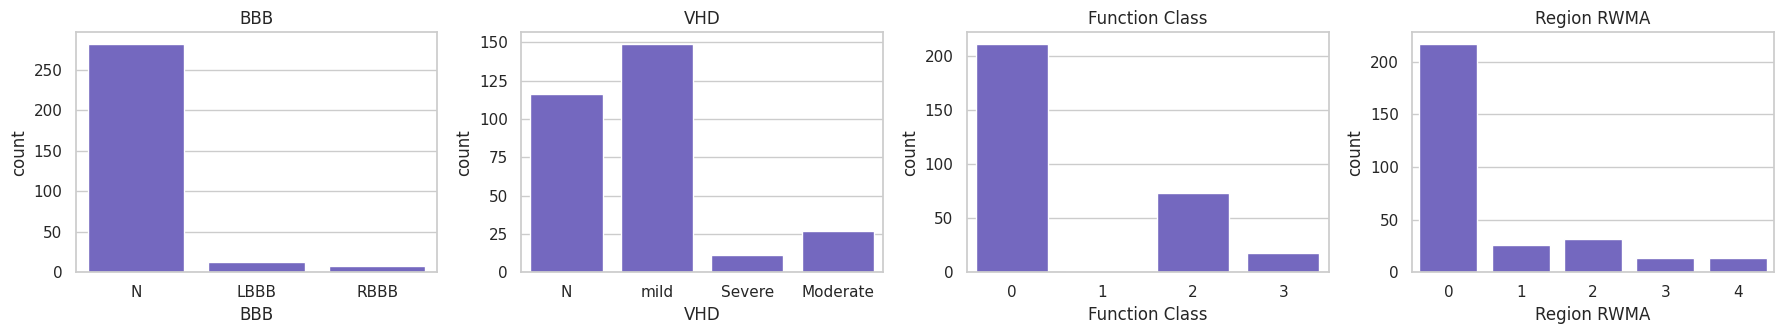

In [28]:
fig,axes = plt.subplots(1,4,figsize=(18,3.5))
for ax,c in zip(axes,['BBB','VHD','Function Class','Region RWMA']):
    sns.countplot(x=df[c],ax=ax,color='slateblue'); ax.set_title(c)
plt.tight_layout(); plt.show()

## 6. Target analysis

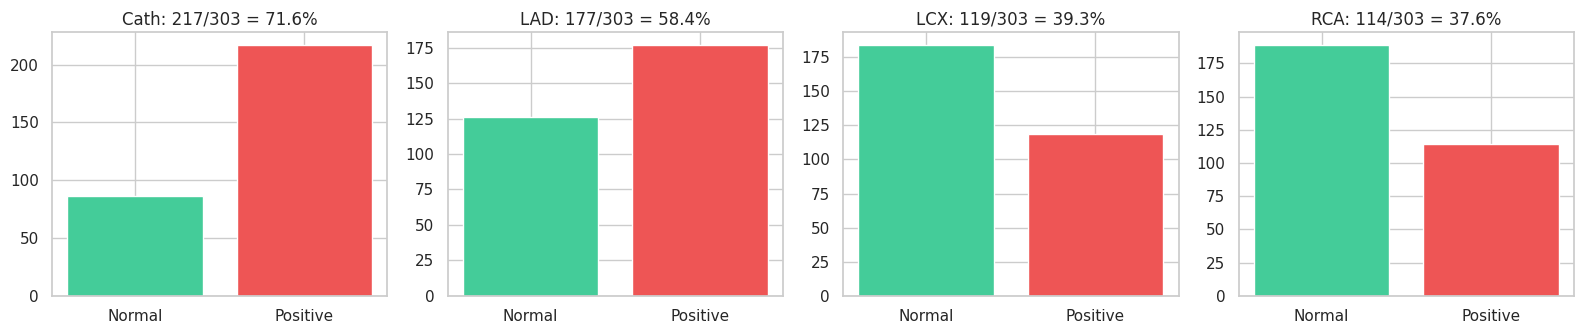

In [29]:
fig,axes = plt.subplots(1,4,figsize=(16,3.5))
for ax,t in zip(axes,TARGETS):
    vc=df[t].value_counts().sort_index(); ax.bar(['Normal','Positive'],vc.values,color=['#4c9','#e55']); ax.set_title(f'{t}: {vc[1]}/{vc.sum()} = {vc[1]/vc.sum():.1%}')
plt.tight_layout(); plt.savefig(FIG/'01_targets.png',dpi=110); plt.show()

In [30]:
df['n_vessels'] = df[['LAD','LCX','RCA']].sum(axis=1)
print(df.n_vessels.value_counts().sort_index())
pat = df.groupby(['LAD','LCX','RCA']).size().rename('n').reset_index(); pat

n_vessels
0    86
1    87
2    67
3    63
Name: count, dtype: int64


,LAD,LCX,RCA,n
0,0,0,0,86
1,0,0,1,17
2,0,1,0,13
3,0,1,1,10
4,1,0,0,57
5,1,0,1,24
6,1,1,0,33
7,1,1,1,63


## 7. Bivariate analysis — every feature vs every target

In [31]:
def cohen_d(a,b):
    s=np.sqrt(((len(a)-1)*a.var()+(len(b)-1)*b.var())/(len(a)+len(b)-2)); return (a.mean()-b.mean())/s if s>0 else 0
def cramers_v(x,y):
    ct=pd.crosstab(x,y); chi2=stats.chi2_contingency(ct,correction=False)[0]; n=ct.values.sum()
    return np.sqrt(chi2/(n*(min(ct.shape)-1)))
def assoc_table(data,target,numeric,categorical):
    rows=[]
    for c in numeric:
        a,b=data.loc[data[target]==1,c],data.loc[data[target]==0,c]
        rows.append({'feature':c,'kind':'numeric','effect':abs(cohen_d(a,b)),'p_value':stats.mannwhitneyu(a,b).pvalue})
    for c in categorical:
        ct=pd.crosstab(data[c],data[target])
        rows.append({'feature':c,'kind':'categorical','effect':cramers_v(data[c],data[target]),'p_value':stats.chi2_contingency(ct)[1]})
    return pd.DataFrame(rows).sort_values('effect',ascending=False).reset_index(drop=True)
cat_like = bin_cols+cat_cols+ord_cols
assoc = {t:assoc_table(df,t,num_cols,cat_like) for t in TARGETS}
assoc['Cath'].head(20)

,feature,kind,effect,p_value
0,Age,numeric,0.860660,5.216475e-10
1,Typical Chest Pain,categorical,0.551594,2.701614e-21
2,BP,numeric,0.543545,7.342546e-06
3,EF-TTE,numeric,0.538463,9.553421e-08
4,FBS,numeric,0.455337,5.986669e-05
5,Atypical,categorical,0.422239,5.524091e-13
6,K,numeric,0.419095,1.109800e-03
7,ESR,numeric,0.392270,3.584605e-04
8,PR,numeric,0.359719,5.945790e-03
9,Region RWMA,categorical,0.336024,6.740776e-07


In [32]:
assoc['LAD'].head(20)

,feature,kind,effect,p_value
0,EF-TTE,numeric,0.670525,2.003948e-10
1,Age,numeric,0.656029,1.449092e-07
2,Typical Chest Pain,categorical,0.459560,3.207498e-15
3,Lymph,numeric,0.381573,1.232143e-03
4,Region RWMA,categorical,0.380121,7.123650e-09
5,PR,numeric,0.369598,2.093030e-03
6,Neut,numeric,0.356705,1.219288e-03
7,ESR,numeric,0.353573,3.131744e-04
8,Atypical,categorical,0.353186,1.727974e-09
9,BP,numeric,0.303350,3.981395e-03


In [33]:
assoc['LCX'].head(20)

,feature,kind,effect,p_value
0,Age,numeric,0.673601,1.040319e-07
1,BP,numeric,0.373028,4.979282e-04
2,CR,numeric,0.365474,1.511232e-02
3,BUN,numeric,0.307886,3.832856e-02
4,FBS,numeric,0.296197,7.474886e-03
5,Typical Chest Pain,categorical,0.292819,6.390490e-07
6,PLT,numeric,0.265852,2.942680e-03
7,EF-TTE,numeric,0.258146,8.355166e-03
8,TG,numeric,0.234824,8.866025e-03
9,K,numeric,0.225921,1.030510e-01


In [34]:
assoc['RCA'].head(20)

,feature,kind,effect,p_value
0,Neut,numeric,0.483055,8.064847e-05
1,Age,numeric,0.469274,8.340432e-05
2,Lymph,numeric,0.453420,1.801223e-04
3,ESR,numeric,0.385712,8.997565e-04
4,FBS,numeric,0.306051,2.442956e-03
5,Typical Chest Pain,categorical,0.291172,7.444240e-07
6,TG,numeric,0.286495,5.432006e-02
7,DM,categorical,0.270428,4.704317e-06
8,WBC,numeric,0.262856,1.611058e-02
9,EF-TTE,numeric,0.252465,1.907653e-02


In [35]:
# side-by-side top-10 per target (numeric effect = |Cohen d|, categorical effect = Cramér's V: indicative, not strictly comparable)
top = pd.concat({t:assoc[t].head(10)[['feature','effect']].reset_index(drop=True) for t in TARGETS},axis=1); top

Cath                           LAD                           LCX                           RCA          
              feature    effect             feature    effect             feature    effect             feature    effect
0                 Age  0.860660              EF-TTE  0.670525                 Age  0.673601                Neut  0.483055
1  Typical Chest Pain  0.551594                 Age  0.656029                  BP  0.373028                 Age  0.469274
2                  BP  0.543545  Typical Chest Pain  0.459560                  CR  0.365474               Lymph  0.453420
3              EF-TTE  0.538463               Lymph  0.381573                 BUN  0.307886                 ESR  0.385712
4                 FBS  0.455337         Region RWMA  0.380121                 FBS  0.296197                 FBS  0.306051
5            Atypical  0.422239                  PR  0.369598  Typical Chest Pain  0.292819  Typical Chest Pain  0.291172
6                   K  0.419095                Neut  0.356705                 PLT  0.265852                  TG  0.286495
7                 ESR  0.392270                 ESR  0.353573              EF-TTE  0.258146                  DM  0.270428
8                  PR  0.359719            Atypical  0.353186                  TG  0.234824                 WBC  0.262856
9         Region RWMA  0.336024                  BP  0.303350                   K  0.225921              EF-TTE  0.252465

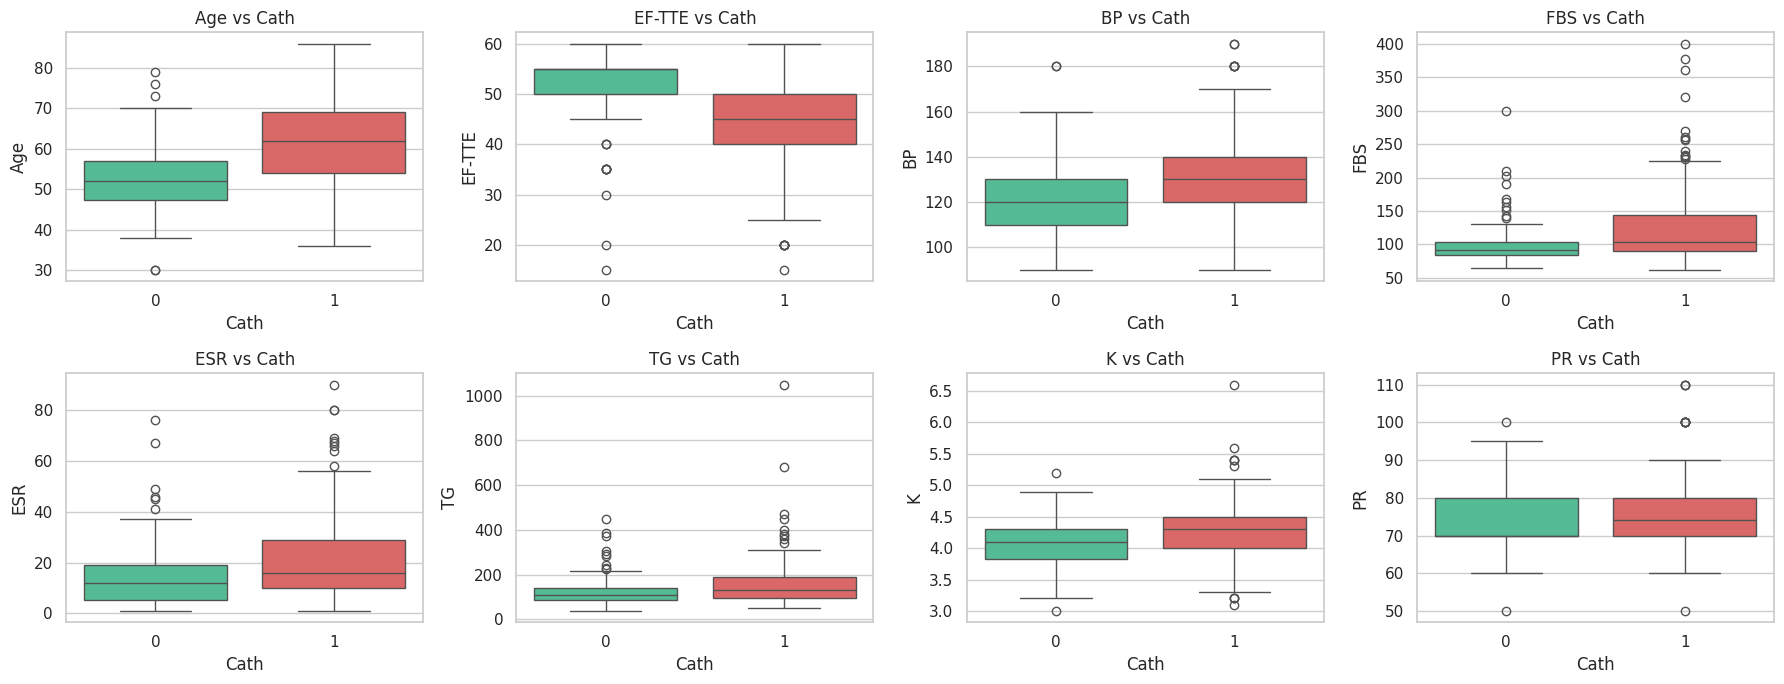

In [36]:
fig,axes = plt.subplots(2,4,figsize=(18,7))
for ax,c in zip(axes.ravel(),['Age','EF-TTE','BP','FBS','ESR','TG','K','PR']):
    sns.boxplot(data=df,x='Cath',y=c,ax=ax,palette=['#4c9','#e55']); ax.set_title(f'{c} vs Cath')
plt.tight_layout(); plt.savefig(FIG/'01_box_vs_cath.png',dpi=110); plt.show()

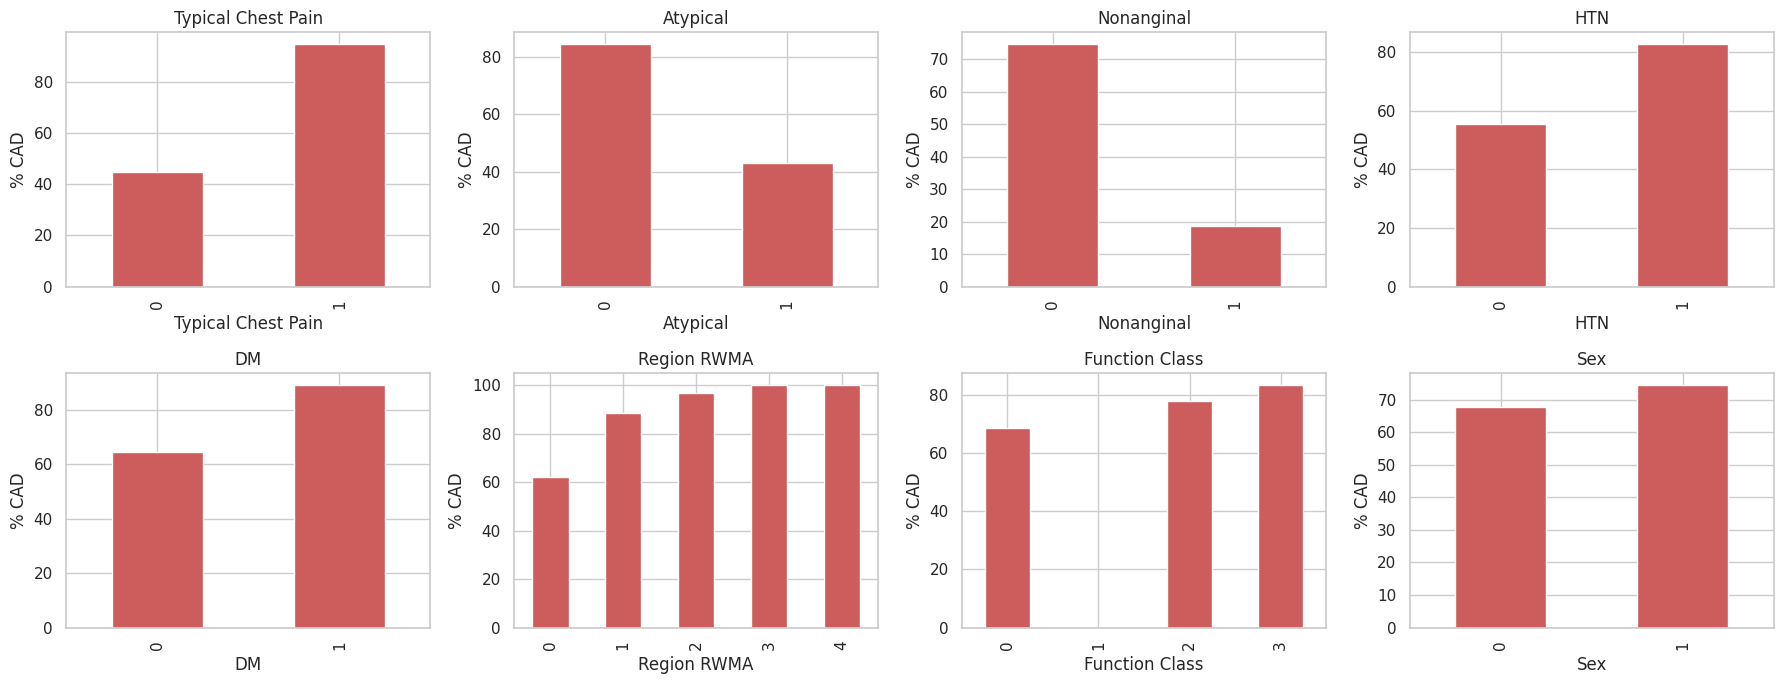

In [37]:
fig,axes = plt.subplots(2,4,figsize=(18,7))
for ax,c in zip(axes.ravel(),['Typical Chest Pain','Atypical','Nonanginal','HTN','DM','Region RWMA','Function Class','Sex']):
    (df.groupby(c)['Cath'].mean()*100).plot.bar(ax=ax,color='indianred'); ax.set_ylabel('% CAD'); ax.set_title(c)
plt.tight_layout(); plt.show()

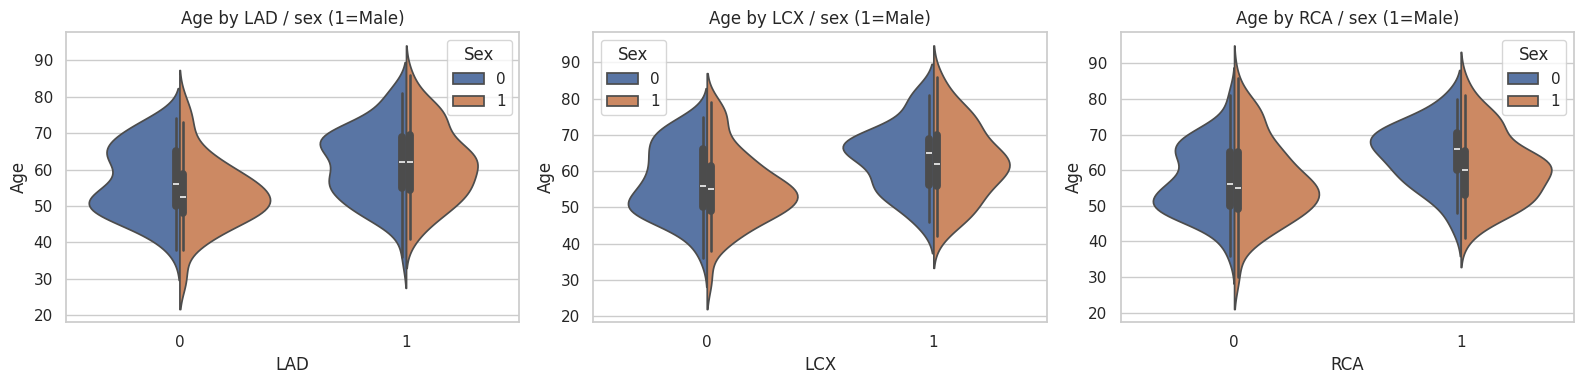

In [38]:
# Age vs target by sex, per vessel
fig,axes = plt.subplots(1,3,figsize=(16,4))
for ax,t in zip(axes,['LAD','LCX','RCA']):
    sns.violinplot(data=df,x=t,y='Age',hue='Sex',split=True,ax=ax); ax.set_title(f'Age by {t} / sex (1=Male)')
plt.tight_layout(); plt.show()

## 8. Correlation and redundancy

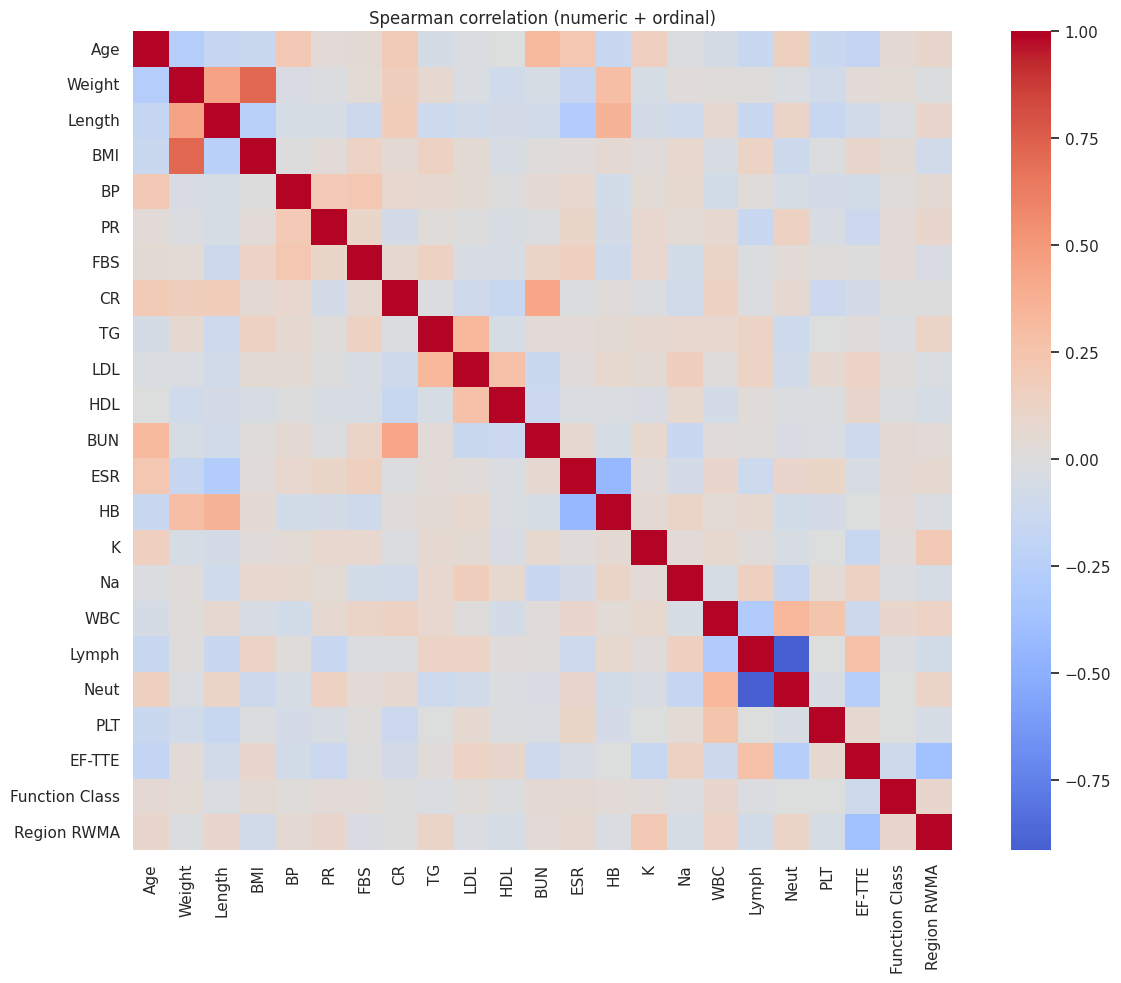

In [39]:
plt.figure(figsize=(13,10))
sp = df[num_cols+ord_cols].corr(method='spearman')
sns.heatmap(sp,cmap='coolwarm',center=0,annot=False,square=True); plt.title('Spearman correlation (numeric + ordinal)')
plt.tight_layout(); plt.savefig(FIG/'01_spearman.png',dpi=110); plt.show()

In [40]:
pairs = sp.where(np.triu(np.ones(sp.shape),1).astype(bool)).stack().rename('rho').reset_index()
pairs['abs']=pairs.rho.abs(); pairs.sort_values('abs',ascending=False).head(12)

,level_0,level_1,rho,abs
238,Lymph,Neut,-0.912341,0.912341
23,Weight,BMI,0.719634,0.719634
22,Weight,Length,0.451699,0.451699
198,ESR,HB,-0.437975,0.437975
136,CR,BUN,0.426386,0.426386
251,EF-TTE,Region RWMA,-0.380419,0.380419
53,Length,HB,0.359773,0.359773
233,WBC,Neut,0.334754,0.334754
148,TG,LDL,0.333907,0.333907
10,Age,BUN,0.312999,0.312999


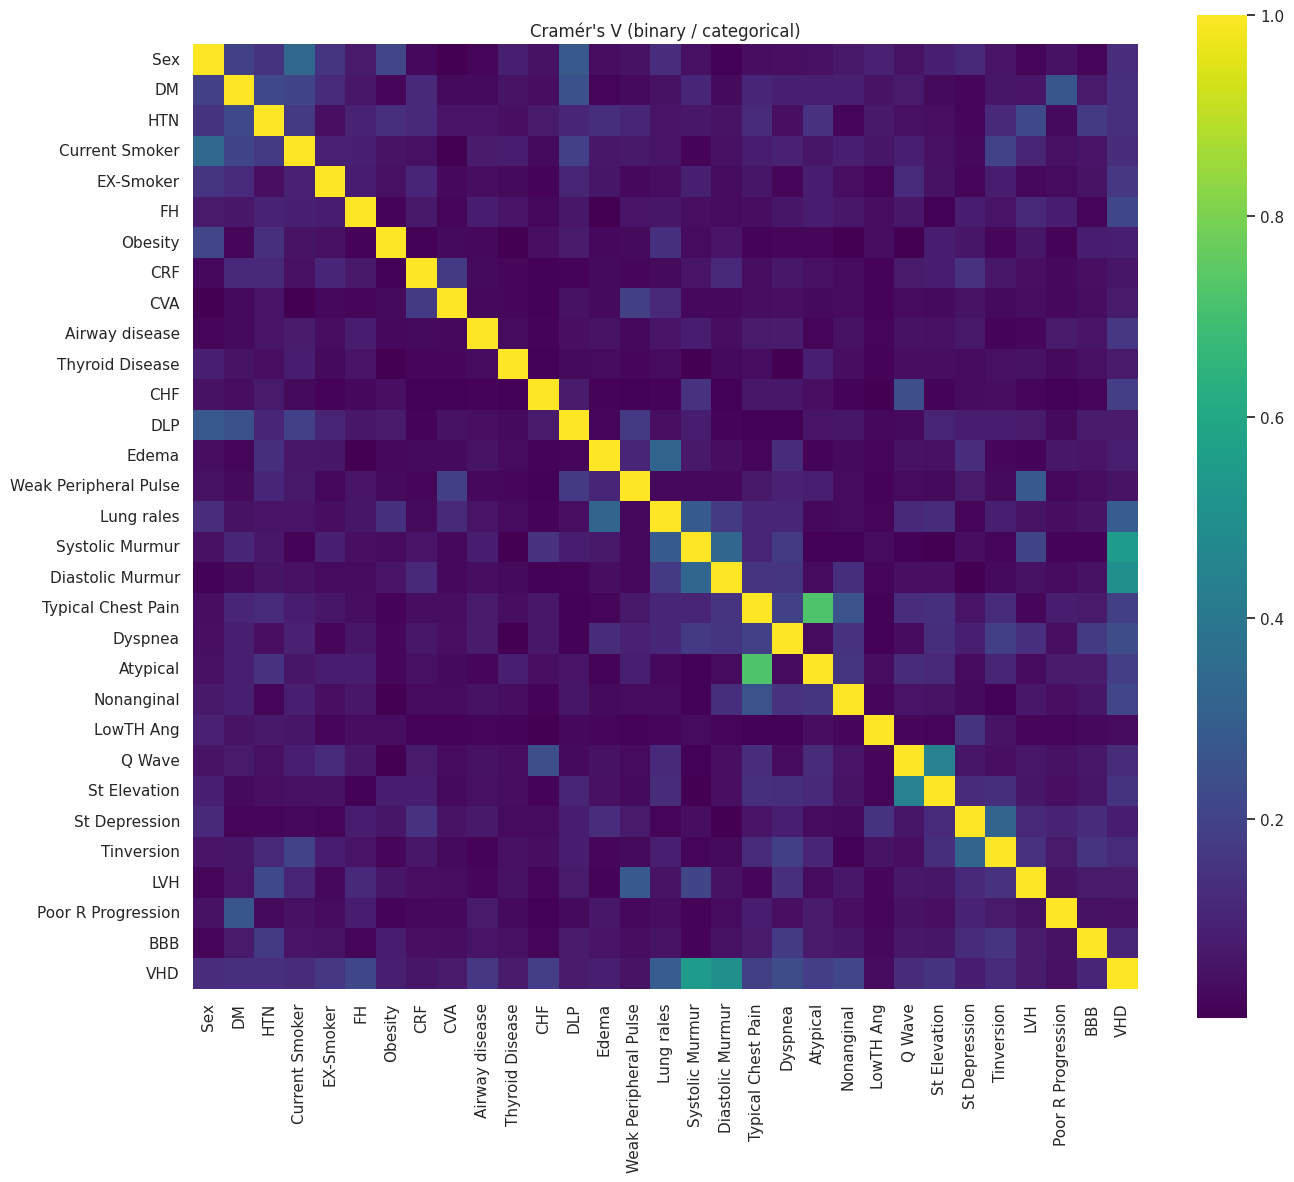

In [41]:
cv_cols = bin_cols+cat_cols
cm = pd.DataFrame(np.eye(len(cv_cols)),index=cv_cols,columns=cv_cols)
for i,a in enumerate(cv_cols):
    for b in cv_cols[i+1:]:
        try: cm.loc[a,b]=cm.loc[b,a]=cramers_v(df[a],df[b])
        except Exception: cm.loc[a,b]=cm.loc[b,a]=np.nan
plt.figure(figsize=(14,12)); sns.heatmap(cm,cmap='viridis',square=True); plt.title("Cramér's V (binary / categorical)")
plt.tight_layout(); plt.savefig(FIG/'01_cramers.png',dpi=110); plt.show()

In [42]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X = StandardScaler().fit_transform(df[num_cols]); X = np.c_[np.ones(len(X)),X]
vif = pd.Series([variance_inflation_factor(X,i) for i in range(1,X.shape[1])],index=num_cols,name='VIF').sort_values(ascending=False)
vif.head(10)

Weight    97.302139
BMI       82.386940
Length    49.787948
Neut       7.586474
Lymph      7.437581
BUN        1.639577
CR         1.622139
WBC        1.447868
HB         1.434236
Age        1.409138
Name: VIF, dtype: float64

`BMI` is an exact function of `Weight` and `Length` (VIF very high) → keep BMI, drop Weight/Length. `Neut` and `Lymph` are strongly (negatively) correlated, which motivates the neutrophil-to-lymphocyte ratio.

## 9. Feature engineering

In [43]:
fe = df.copy()
# chest-pain type: the three indicators are mutually exclusive in this data, 30 patients have none
fe['CP_type'] = np.select([fe['Typical Chest Pain']==1, fe.Atypical==1, fe.Nonanginal==1],['Typical','Atypical','Nonanginal'],'NoCP')
fe['NLR']      = fe.Neut/fe.Lymph
fe['TG_HDL']   = fe.TG/fe.HDL
fe['LDL_HDL']  = fe.LDL/fe.HDL
fe['pulse_pressure_proxy'] = fe.BP/fe.PR
fe['risk_factor_count'] = fe[['DM','HTN','Current Smoker','FH','DLP','Obesity']].sum(axis=1)
ecg = ['Q Wave','St Elevation','St Depression','Tinversion','LVH','Poor R Progression']
fe['ecg_abnormal_count'] = fe[ecg].sum(axis=1) + (fe.BBB!='N').astype(int)
fe['age_group'] = pd.cut(fe.Age,[0,45,55,65,120],labels=['<=45','46-55','56-65','>65']).astype(str)
fe['symptom_score'] = fe['Typical Chest Pain']*2 + fe.Atypical + fe['Function Class'] + fe.Dyspnea
fe['ef_low'] = (fe['EF-TTE']<50).astype(int)
fe = fe.drop(columns=['Weight','Length'])
new = ['NLR','TG_HDL','LDL_HDL','pulse_pressure_proxy','risk_factor_count','ecg_abnormal_count','symptom_score','ef_low']
fe[new+['CP_type','age_group']].describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
NLR,303.0,NaN,NaN,NaN,2.244218,1.511059,0.568966,1.371711,1.848485,2.537088,12.142857
TG_HDL,303.0,NaN,NaN,NaN,3.986468,2.710964,0.5,2.237693,3.181818,4.77971,23.863636
LDL_HDL,303.0,NaN,NaN,NaN,2.706257,1.023668,0.576923,2.0,2.564103,3.214559,6.226415
pulse_pressure_proxy,303.0,NaN,NaN,NaN,1.740756,0.283836,0.9,1.571429,1.714286,1.870833,2.666667
risk_factor_count,303.0,NaN,NaN,NaN,2.320132,1.147914,0.0,2.0,2.0,3.0,5.0
ecg_abnormal_count,303.0,NaN,NaN,NaN,0.79538,0.787555,0.0,0.0,1.0,1.0,3.0
symptom_score,303.0,NaN,NaN,NaN,2.49505,1.441741,0.0,1.0,2.0,4.0,6.0
ef_low,303.0,NaN,NaN,NaN,0.419142,0.494235,0.0,0.0,0.0,1.0,1.0
CP_type,303,4,Typical,164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age_group,303,4,46-55,103,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [44]:
# do the engineered features carry signal? (compare with the best raw features)
print(assoc_table(fe,'Cath',new,['CP_type','age_group']).to_string())
print(assoc_table(fe,'LAD',new,['CP_type','age_group']).head(5).to_string())

                feature         kind    effect       p_value
0    ecg_abnormal_count      numeric  0.699493  9.067511e-08
1         symptom_score      numeric  0.651372  2.319762e-08
2                ef_low      numeric  0.651190  9.128399e-07
3               CP_type  categorical  0.582314  3.993617e-22
4     risk_factor_count      numeric  0.576903  1.081459e-05
5             age_group  categorical  0.347106  5.852734e-08
6                TG_HDL      numeric  0.285418  3.863253e-03
7                   NLR      numeric  0.265690  1.886612e-02
8  pulse_pressure_proxy      numeric  0.256356  1.291017e-02
9               LDL_HDL      numeric  0.032264  7.506480e-01
              feature         kind    effect       p_value
0              ef_low      numeric  0.723164  4.891084e-09
1  ecg_abnormal_count      numeric  0.675834  3.869197e-08
2       symptom_score      numeric  0.518393  8.544432e-07
3             CP_type  categorical  0.481721  3.658572e-15
4                 NLR      numeric

In [45]:
print('CP_type vs Cath (% CAD):'); print((fe.groupby('CP_type').Cath.agg(['mean','count'])).round(3))

CP_type vs Cath (% CAD):
             mean  count
CP_type                 
Atypical    0.430     93
NoCP        0.633     30
Nonanginal  0.188     16
Typical     0.945    164


## 10. Leakage guard

In [46]:
AUDIT = ['Cath_original','label_corrected','n_vessels']
ALL_LABELS = TARGETS+AUDIT
feature_df = fe.drop(columns=ALL_LABELS)
FEATURES = list(feature_df.columns)
assert not set(FEATURES)&set(ALL_LABELS), 'target leak!'
print(len(FEATURES),'input features; none of',ALL_LABELS,'is an input')

62 input features; none of ['Cath', 'LAD', 'LCX', 'RCA', 'Cath_original', 'label_corrected', 'n_vessels'] is an input


## 11. Stratified train / test split

In [47]:
# stratify on the vessel pattern LAD x LCX x RCA: it determines Cath and keeps all 4 target ratios close
strat = fe.LAD.astype(str)+fe.LCX.astype(str)+fe.RCA.astype(str)
print(strat.value_counts().to_dict())
idx_tr, idx_te = train_test_split(fe.index, test_size=0.20, stratify=strat, random_state=SEED)
fe['split'] = np.where(fe.index.isin(idx_te),'test','train')
print(fe.split.value_counts().to_dict())
pd.concat({t:fe.groupby('split')[t].mean().round(3) for t in TARGETS},axis=1)

{'000': 86, '111': 63, '100': 57, '110': 33, '101': 24, '001': 17, '010': 13, '011': 10}
{'train': 242, 'test': 61}


,Cath,LAD,LCX,RCA
split,,,,
test,0.721,0.590,0.410,0.377
train,0.715,0.583,0.388,0.376


## 12. Preprocessing pipeline: `fit`, `fit_transform`, `transform`

In [48]:
skew_cols = ['FBS','TG','ESR','WBC','PLT','CR','TG_HDL','NLR','LDL_HDL']            # log1p then scale
scale_cols = [c for c in num_cols if c in FEATURES and c not in skew_cols]+['pulse_pressure_proxy','risk_factor_count','ecg_abnormal_count','symptom_score']
ordinal_cols = ['VHD','Function Class','Region RWMA']
nominal_cols = ['BBB','CP_type','age_group']
binary_cols  = [c for c in FEATURES if c not in skew_cols+scale_cols+ordinal_cols+nominal_cols]
assert sorted(skew_cols+scale_cols+ordinal_cols+nominal_cols+binary_cols)==sorted(FEATURES)
print(len(skew_cols),len(scale_cols),len(ordinal_cols),len(nominal_cols),len(binary_cols))

9 17 3 3 30


In [49]:
def build_preprocessor():
    return ColumnTransformer([
        ('skew', Pipeline([('log',FunctionTransformer(np.log1p,feature_names_out='one-to-one')),('sc',StandardScaler())]), skew_cols),
        ('num',  StandardScaler(), scale_cols),
        ('ord',  Pipeline([('enc',OrdinalEncoder(categories=[['N','mild','Moderate','Severe'],[0,1,2,3],[0,1,2,3,4]])),('sc',StandardScaler())]), ordinal_cols),
        ('nom',  OneHotEncoder(handle_unknown='ignore',sparse_output=False), nominal_cols),
        ('bin',  'passthrough', binary_cols)], verbose_feature_names_out=False)
X_train = fe.loc[fe.split=='train',FEATURES]; X_test = fe.loc[fe.split=='test',FEATURES]
prep = build_preprocessor()
prep.fit(X_train)                                  # learn means/stds/categories from TRAIN only
Xtr_t = prep.transform(X_train)                    # equals fit_transform(X_train)
Xte_t = prep.transform(X_test)                     # test is only transformed
print(Xtr_t.shape, Xte_t.shape)

(242, 70) (61, 70)


In [50]:
assert np.allclose(Xtr_t, build_preprocessor().fit_transform(X_train))      # fit().transform() == fit_transform()
names = prep.get_feature_names_out()
tr = pd.DataFrame(Xtr_t,columns=names); te = pd.DataFrame(Xte_t,columns=names)
chk = pd.DataFrame({'train_mean':tr[skew_cols+scale_cols].mean(),'train_std':tr[skew_cols+scale_cols].std(),
                    'test_mean':te[skew_cols+scale_cols].mean(),'test_std':te[skew_cols+scale_cols].std()}).round(3)
chk.head(12)

,train_mean,train_std,test_mean,test_std
FBS,-0.0,1.002,-0.014,0.920
TG,0.0,1.002,0.102,0.902
ESR,-0.0,1.002,-0.028,1.002
WBC,-0.0,1.002,-0.036,0.851
PLT,0.0,1.002,-0.041,0.759
CR,-0.0,1.002,-0.254,0.880
TG_HDL,0.0,1.002,0.082,0.979
NLR,0.0,1.002,0.081,1.113
LDL_HDL,-0.0,1.002,-0.105,0.925
Age,0.0,1.002,0.008,0.893


In [51]:
assert tr[skew_cols+scale_cols].mean().abs().max()<1e-8
print('train means≈0, std≈1; test means deviate slightly -> test statistics were NOT used for fitting')
print('encoded feature count:',len(names)); list(names)

train means≈0, std≈1; test means deviate slightly -> test statistics were NOT used for fitting
encoded feature count: 70


['FBS',
 'TG',
 'ESR',
 'WBC',
 'PLT',
 'CR',
 'TG_HDL',
 'NLR',
 'LDL_HDL',
 'Age',
 'BMI',
 'BP',
 'PR',
 'LDL',
 'HDL',
 'BUN',
 'HB',
 'K',
 'Na',
 'Lymph',
 'Neut',
 'EF-TTE',
 'pulse_pressure_proxy',
 'risk_factor_count',
 'ecg_abnormal_count',
 'symptom_score',
 'VHD',
 'Function Class',
 'Region RWMA',
 'BBB_LBBB',
 'BBB_N',
 'BBB_RBBB',
 'CP_type_Atypical',
 'CP_type_NoCP',
 'CP_type_Nonanginal',
 'CP_type_Typical',
 'age_group_46-55',
 'age_group_56-65',
 'age_group_<=45',
 'age_group_>65',
 'Sex',
 'DM',
 'HTN',
 'Current Smoker',
 'EX-Smoker',
 'FH',
 'Obesity',
 'CRF',
 'CVA',
 'Airway disease',
 'Thyroid Disease',
 'CHF',
 'DLP',
 'Edema',
 'Weak Peripheral Pulse',
 'Lung rales',
 'Systolic Murmur',
 'Diastolic Murmur',
 'Typical Chest Pain',
 'Dyspnea',
 'Atypical',
 'Nonanginal',
 'LowTH Ang',
 'Q Wave',
 'St Elevation',
 'St Depression',
 'Tinversion',
 'LVH',
 'Poor R Progression',
 'ef_low']

## 13. Class imbalance

In [52]:
imb = pd.DataFrame({t:{'positive':int(fe[t].sum()),'negative':int((1-fe[t]).sum()),
        'pos_rate':round(fe[t].mean(),3),'imbalance_ratio(neg/pos)':round((1-fe[t]).sum()/fe[t].sum(),2),
        'scale_pos_weight':round((1-fe.loc[fe.split=='train',t]).sum()/fe.loc[fe.split=='train',t].sum(),2)} for t in TARGETS}).T; imb

,positive,negative,pos_rate,imbalance_ratio(neg/pos),scale_pos_weight
Cath,217.0,86.0,0.716,0.40,0.40
LAD,177.0,126.0,0.584,0.71,0.72
LCX,119.0,184.0,0.393,1.55,1.57
RCA,114.0,189.0,0.376,1.66,1.66


In [53]:
# SMOTE demonstration on the TRAIN set only (inside model CV it lives in the pipeline)
for t in TARGETS:
    ytr = fe.loc[fe.split=='train',t]
    Xs,ys = SMOTE(random_state=SEED,k_neighbors=5).fit_resample(Xtr_t,ytr)
    print(f'{t}: before {dict(ytr.value_counts().sort_index())}  after SMOTE {dict(pd.Series(ys).value_counts().sort_index())}')

Cath: before {0: np.int64(69), 1: np.int64(173)}  after SMOTE {0: np.int64(173), 1: np.int64(173)}
LAD: before {0: np.int64(101), 1: np.int64(141)}  after SMOTE {0: np.int64(141), 1: np.int64(141)}
LCX: before {0: np.int64(148), 1: np.int64(94)}  after SMOTE {0: np.int64(148), 1: np.int64(148)}
RCA: before {0: np.int64(151), 1: np.int64(91)}  after SMOTE {0: np.int64(151), 1: np.int64(151)}


**Class-handling strategy for modelling:** the imbalance is moderate (Cath 71/29, LAD 58/42, LCX 39/61, RCA 38/62), so no single treatment is assumed best. Each model notebook tunes *none* vs *class weights / scale_pos_weight* vs *SMOTE* as a pipeline hyper-parameter, and chooses the decision threshold from out-of-fold train probabilities.

## 14. Save outputs

In [54]:
clean = fe.reset_index().rename(columns={'index':'patient_idx'})
clean = clean[['patient_idx']+FEATURES+ALL_LABELS+['split']]
clean.to_csv(OUT/'cad_clean.csv',index=False)
trans_tr = tr.copy(); trans_tr[TARGETS]=fe.loc[fe.split=='train',TARGETS].values
trans_te = te.copy(); trans_te[TARGETS]=fe.loc[fe.split=='test',TARGETS].values
trans_tr.to_csv(OUT/'cad_train_transformed.csv',index=False); trans_te.to_csv(OUT/'cad_test_transformed.csv',index=False)
report = profile.copy(); report['paper_range_ok']=report.index.map(lambda c: dict(zip(rc.feature,rc.within_range)).get(c,np.nan))
report.to_csv(OUT/'data_quality_report.csv')
print(clean.shape, trans_tr.shape, trans_te.shape)

(303, 71) (242, 74) (61, 74)


In [55]:
chk = pd.read_csv(OUT/'cad_clean.csv')
assert len(chk)==303 and chk.label_corrected.sum()==1
assert ((chk.LAD|chk.LCX|chk.RCA)==chk.Cath).all()
assert not set(TARGETS)&set(FEATURES)
print('all assertions passed'); chk.head()

all assertions passed


,patient_idx,Age,Sex,BMI,DM,HTN,Current Smoker,EX-Smoker,FH,Obesity,CRF,CVA,Airway disease,Thyroid Disease,CHF,DLP,BP,PR,Edema,Weak Peripheral Pulse,Lung rales,Systolic Murmur,Diastolic Murmur,Typical Chest Pain,Dyspnea,Function Class,Atypical,Nonanginal,LowTH Ang,Q Wave,St Elevation,St Depression,Tinversion,LVH,Poor R Progression,BBB,FBS,CR,TG,LDL,HDL,BUN,ESR,HB,K,Na,WBC,Lymph,Neut,PLT,EF-TTE,Region RWMA,VHD,CP_type,NLR,TG_HDL,LDL_HDL,pulse_pressure_proxy,risk_factor_count,ecg_abnormal_count,age_group,symptom_score,ef_low,Cath,LAD,LCX,RCA,Cath_original,label_corrected,n_vessels,split
0,0,53,1,29.387755,0,1,1,0,0,1,0,0,0,0,0,1,110,80,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,N,90,0.7,250,155,30.0,8,7,15.6,4.7,141,5700,39,52,261,50,0,N,NoCP,1.333333,8.333333,5.166667,1.375,4,2,46-55,0,0,1,1,0,1,1,0,2,train
1,1,67,0,28.398718,0,1,0,0,0,1,0,0,0,0,0,0,140,80,1,0,0,0,0,1,0,0,0,0,0,0,0,1,1,0,0,N,80,1.0,309,121,36.0,30,26,13.9,4.7,156,7700,38,55,165,40,4,N,Typical,1.447368,8.583333,3.361111,1.750,2,2,>65,2,1,1,1,1,0,1,0,2,test
2,2,54,1,20.077335,0,0,1,0,0,0,0,0,0,0,0,0,100,100,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,N,85,1.0,103,70,45.0,17,10,13.5,4.7,139,7400,38,60,230,40,2,mild,Typical,1.578947,2.288889,1.555556,1.000,1,0,46-55,2,1,1,1,0,0,1,0,1,test
3,3,66,0,26.838648,0,1,0,0,0,1,0,0,0,0,0,0,100,80,0,0,0,0,1,0,1,3,0,1,0,0,0,1,0,0,0,N,78,1.2,63,55,27.0,30,76,12.1,4.4,142,13000,18,72,742,55,0,Severe,Nonanginal,4.000000,2.333333,2.037037,1.250,2,1,>65,4,0,0,0,0,0,0,0,0,train
4,4,50,0,37.165193,0,1,0,0,0,1,0,0,0,0,0,0,110,80,0,0,0,1,0,0,1,2,0,0,0,0,0,0,0,0,0,N,104,1.0,170,110,50.0,16,27,13.2,4.0,140,9200,55,39,274,50,0,Severe,NoCP,0.709091,3.400000,2.200000,1.375,2,0,46-55,3,0,0,0,0,0,0,0,0,test


## Summary
* 303 patients, no missing values, no duplicates; `Sheet1` (extended schema) is empty and ignored.
* One label inconsistency (row 93) fixed per the UCI/paper definition and logged.
* `Fmale` normalised, constant `Exertional CP` dropped, Y/N encoded, BMI kept / Weight+Length dropped.
* New features: `CP_type, NLR, TG_HDL, LDL_HDL, pulse_pressure_proxy, risk_factor_count, ecg_abnormal_count, symptom_score, ef_low, age_group`.
* Leakage guard in place; one frozen 80/20 split in `cad_clean.csv`; preprocessing is rebuilt inside each model pipeline.